# Ray Serve: FastAPI ingress with a route prefix

A FastAPI app, built on each replica by a builder function, becomes the HTTP ingress of a deployment served under the /api route prefix.

**When to use it.** REST endpoints with typed parameters, validation and OpenAPI docs in front of Ray-scaled code.

Why a builder function: on Ray 2.55.1, `@serve.ingress(app)` with a module-level FastAPI app object fails to pickle with current FastAPI releases, so this pattern passes a function that creates the app on each replica.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

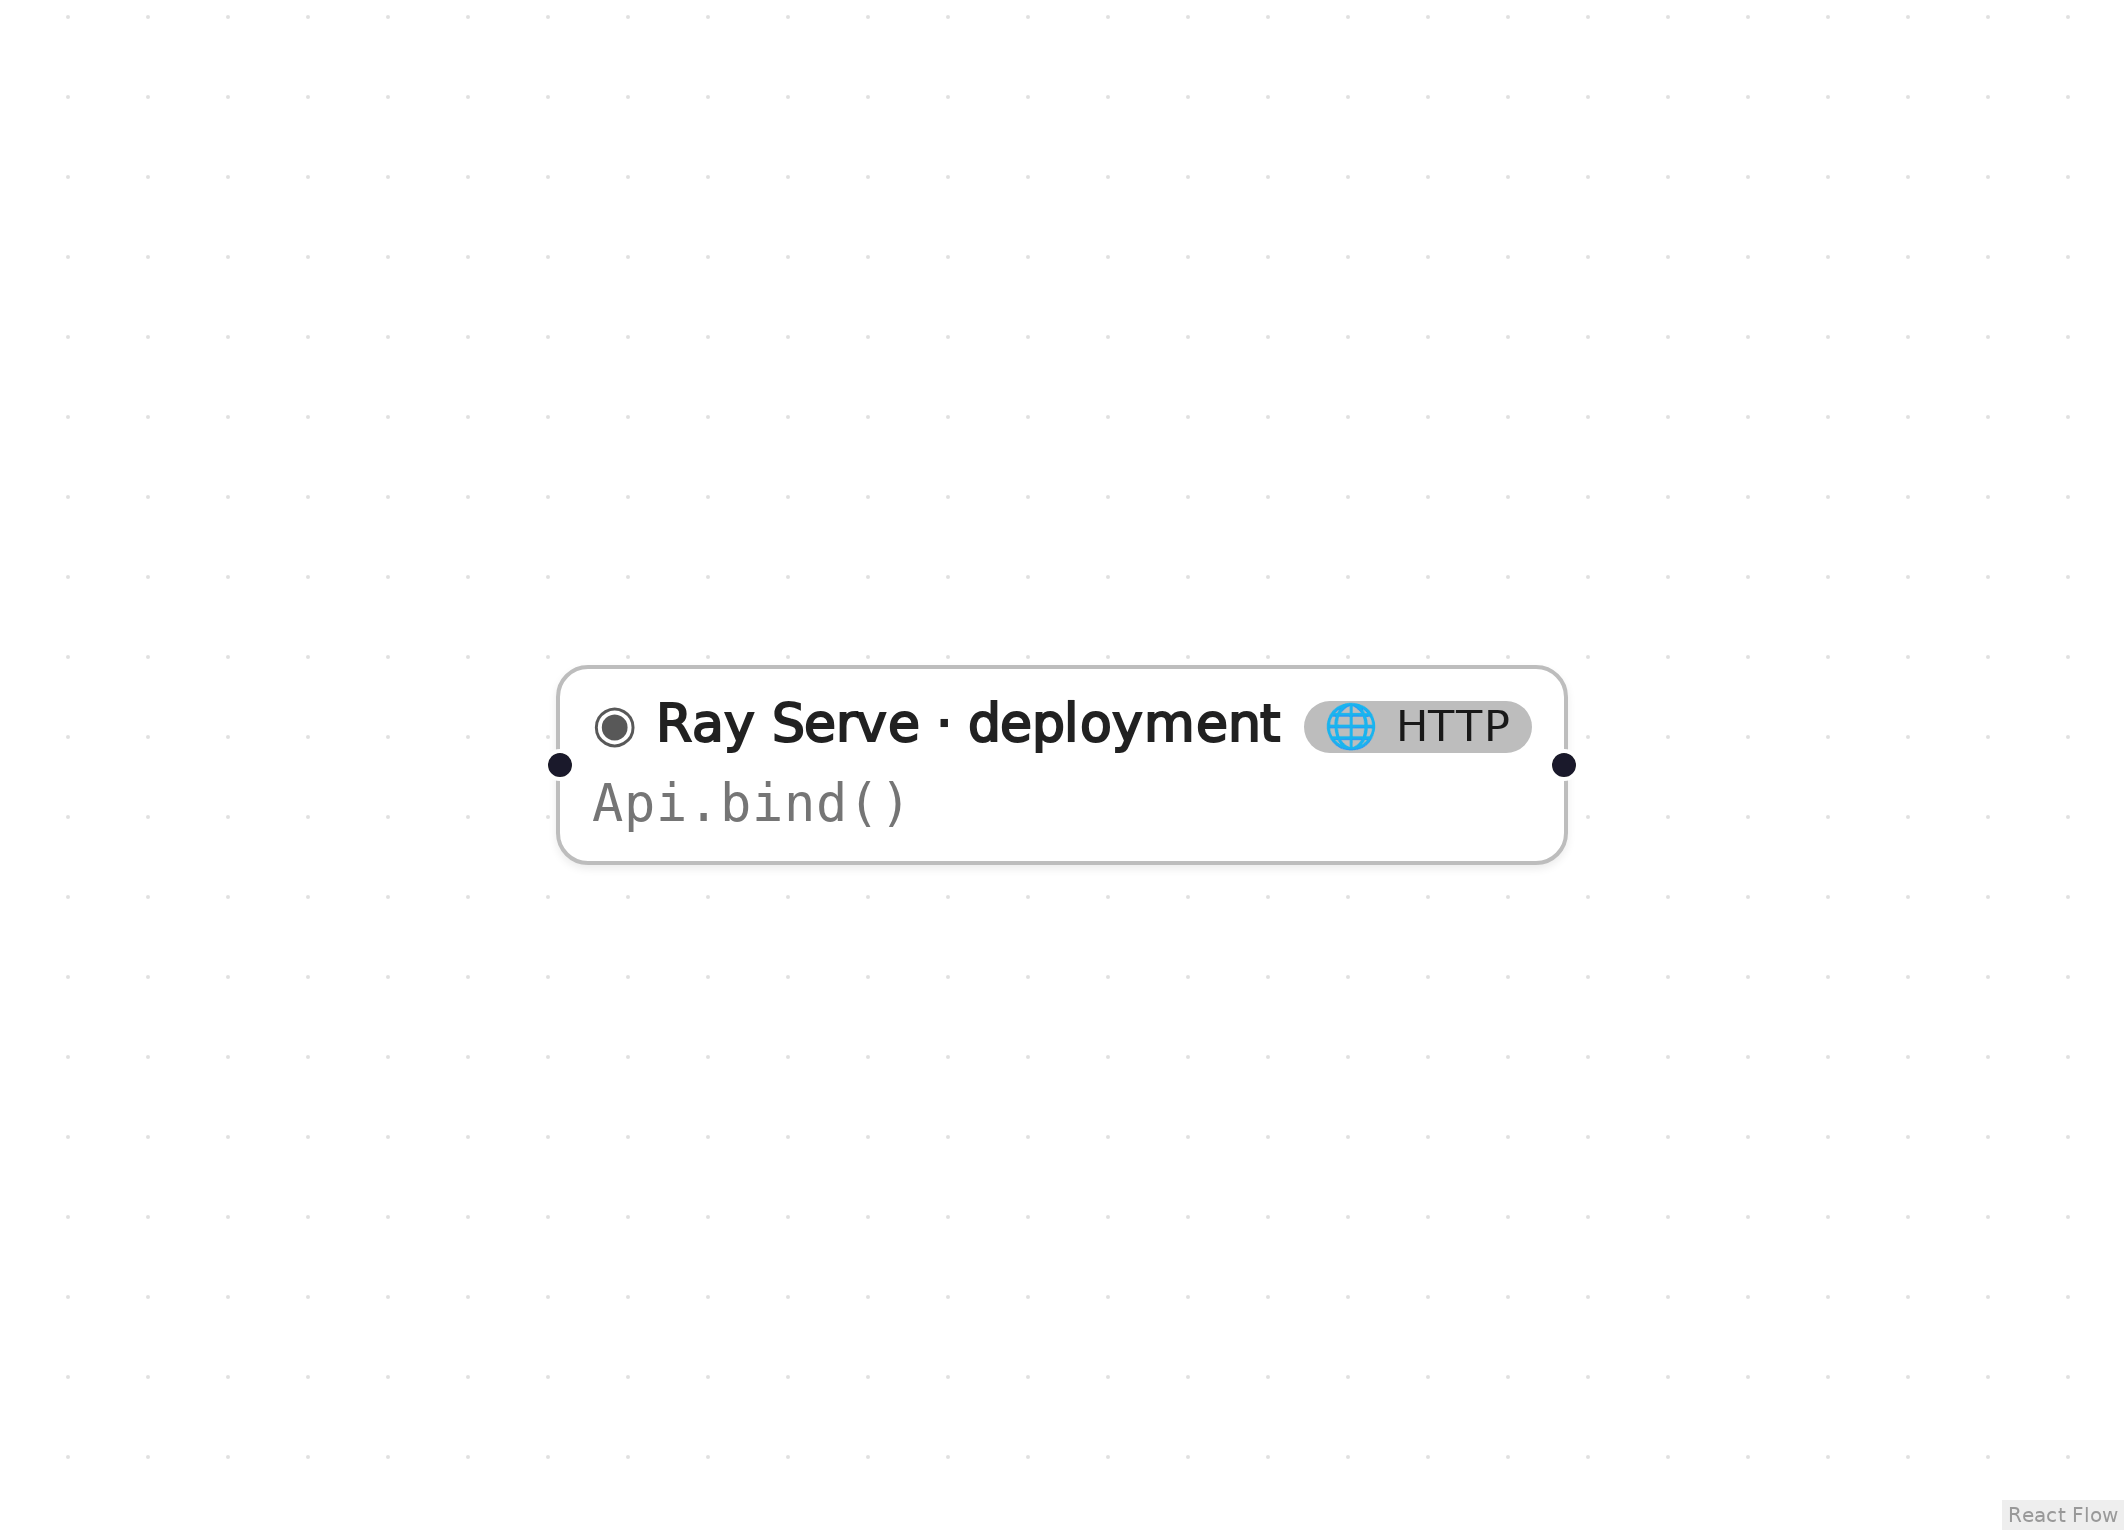

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
from fastapi import FastAPI
from ray import serve


def build_app():
    # A builder function: Serve calls it on each replica, so the FastAPI app object never
    # has to be pickled (with Ray 2.55.1, pickling an app from current FastAPI releases fails).
    app = FastAPI()

    @app.get("/hello")
    def hello(name: str = "world") -> dict:
        return {"greeting": f"hello {name}"}

    return app


@serve.deployment
@serve.ingress(build_app)
class Api:
    pass

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

from ray import serve
import ray

if not ray.is_initialized():
    ray.init()

_deploy_n1 = Api.bind()
serve.run(_deploy_n1, route_prefix="/api")

DeploymentHandle(deployment='Api')

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
import json
import urllib.request

with urllib.request.urlopen("http://127.0.0.1:8000/api/hello?name=ray", timeout=30) as resp:
    body = json.loads(resp.read())
assert body == {"greeting": "hello ray"}, body
print(body)

{'greeting': 'hello ray'}


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
from ray import serve
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Deployment** (node `n1`, lines 9–10)

```python
_deploy_n1 = Api.bind()
serve.run(_deploy_n1, route_prefix="/api")
```

serve.run(..., route_prefix="/api") mounts the deployment under /api; the routes of the FastAPI app returned by build_app handle the rest of the path.

## Clean up

Shut down Serve and then Ray, so the next notebook starts fresh.

In [5]:
from ray import serve

serve.shutdown()
ray.shutdown()